In [2]:
import numpy as np
import os
import pickle
import matplotlib.pyplot as plt
import networkx as nx
from itertools import combinations
import random
import graphlet_counts
from sampling import Sample
from graphlet_counts import three_counts, four_counts
from funciones import arista_nueva, add_node, grados_tras, aplicar, dist_grados, histograma_bins, dentro, construir_valid, contar_T

### Costo

In [3]:
# Wasserstein-Wesfeler-Lehman graph kernel (Explicarla, ver qué mide)

# Tiempos de ejecución (Comparacion de orden de graphlets)

def Cost(P, gl, P_target, P_bounds, E_gl, bounds_gl, w):
    """
    P         : distribución de grados (en bins) del grafo evaluado
    gl        : conteos de graphlets del grafo evaluado
    P_target  : E_p, distribución de grados media del objetivo (en bins)
    P_bounds  : no se usa; se deja para mantener la firma
    E_gl      : Ec, conteos medios de graphlets del objetivo
    bounds_gl : 2*sc, semiancho completo (el intervalo es E_gl +- bounds_gl)
    w         : peso del término de grados, en [0, 1]
    """
    P = np.asarray(P, dtype=float)
    P_target = np.asarray(P_target, dtype=float)
    gl = np.asarray(gl, dtype=float)
    E_gl = np.asarray(E_gl, dtype=float)
    bounds_gl = np.asarray(bounds_gl, dtype=float)

    # Término de grados (Algoritmo 2, líneas 2-4): distribución acumulada inversa
    Pc = np.cumsum(P[::-1])[::-1]
    Ec_p = np.cumsum(P_target[::-1])[::-1]
    cost_deg = np.mean(np.abs(Pc - Ec_p) / np.maximum(Ec_p, 1e-12))

    # Término de graphlets (líneas 5-13)
    cost_gl = 0.0
    for i in range(len(E_gl)):
        E_c = E_gl[i]
        if E_c == 0:
            continue                      # graphlet ausente en el objetivo: se trata abajo
        g = gl[i]
        b = bounds_gl[i]
        f = max(b / E_c, 1e-3)            # evita log de base 1 cuando sc = 0
        if g < E_c - b:
            c = min(max(g, 0.1), E_c)     # 0.1 evita log(0); el min evita costos negativos
            cost_gl += np.log(c / E_c) / np.log(1 - min(f, 0.99))
        elif g > E_c + b:
            cost_gl += np.log(g / E_c) / np.log(1 + f)
    cost_gl /= len(E_gl)

    # Penalización por graphlets que nunca aparecen en el objetivo
    if np.any(gl[E_gl == 0] > 0):
        cost_gl = max(cost_gl, 1.0) * 10

    return w * cost_deg + (1 - w) * cost_gl

### Bin degrees

In [4]:
#Binado de la distribución de grados EN
def BinDegrees(E_N,S):
    bins = []
    weights = []
    bin_edge = len(E_N)
    bins.append(bin_edge)
    zero_bin = False
    w = 0

    while bin_edge > 1:     # Se asume que hay un typo en el paper
        bin_edge = bin_edge-1
        w = w + E_N[bin_edge]
        if bin_edge == 1 or w >= 1 - 0.1/S or (zero_bin and E_N[bin_edge-1] != 0):
            bins.append(bin_edge)
            weights.append(1 if abs(w-1) < 0.1/S else w)
            w = 0
            zero_bin = (E_N[bin_edge-1] == 0)
    # 1-0.1/S es cercano a 1, se utiliza este pequeño desfase para evitar problemas de redondeo.

    # Los colocamos en orden creciente
    bins = bins[::-1]
    weights = weights[::-1]

    # Recorte de las colas de picos ### HAY QUE ENTENDERLO
    limit = 0.01
    for i in range(len(weights)):
        if bins[i+1] - bins[i] > 1 and weights[i] != 0:
            # cola inferior
            cola_inf = E_N[bins[i]] + E_N[bins[i]+1]
            while cola_inf < limit:
                bins[i] += 1
                cola_inf += E_N[bins[i]+1]
            # cola superior
            cola_sup = E_N[bins[i+1]-1] + E_N[bins[i+1]-2]
            while cola_sup < limit:
                bins[i+1] -= 1
                cola_sup += E_N[bins[i+1]-2]

    return bins, weights

## Graip

In [5]:
def GRAIP(G, S, max_it, node_step, max_rech=None, w=2/3):
    graphlets, valid = construir_valid()

    E_n, s_n, E_m, s_m, Ec, sc, E_N, s_N = Sample(G, S, 8, four_counts)
    bins, weights = BinDegrees(E_N, S)
    bins = np.asarray(bins, dtype=int)
    weights = np.asarray(weights, dtype=float)
    E_p = weights / E_n

    # Cotas completas (el "2s" ya incluido)
    wts = np.where(np.isclose(weights, np.round(weights)), np.round(weights), weights)
    necesario = np.maximum(np.maximum(wts - np.floor(wts), np.ceil(wts) - wts) * 1.1, 0.5)
    cota_nodos = np.where(np.diff(bins) == 1, 2 * s_N[bins[:-1]], necesario)
    s_p = cota_nodos / E_n          # cota de grados, en fracción de nodos
    b_c = 2 * sc                    # cota de graphlets

    CCg = 3 * Ec[1] / (Ec[0] + 3 * Ec[1])
    s_n, s_m = max(s_n, 1e-9), max(s_m, 1e-9)
    if max_rech is None:
        max_rech = max(1, int(0.02 * E_m))

    # Semilla BA con ~20% de nodos y aristas
    N0 = max(round(E_n / 5), 3) #Numero de nodos inicial
    k = max(1, min(round(E_m / E_n), N0 - 1))
    H = nx.barabasi_albert_graph(N0, k)

    C_H = np.asarray(four_counts(H), dtype=float)
    proximo_id = max(H.nodes) + 1
    rechazos = 0
    sig = lambda x: 1 / (1 + np.exp(-np.clip(x, -50, 50)))

    for step in range(1, max_it + 1):
        n, m = H.number_of_nodes(), H.number_of_edges()
        P_H = histograma_bins(dist_grados([d for _, d in H.degree()]), bins)

        if dentro(P_H, E_p, s_p) and dentro(C_H, Ec, b_c):
            return H

        r = random.random()

        if step % node_step == 0:                                   # --- nodo ---
            if r > sig((n - E_n) / s_n):
                u = proximo_id
                op = {"tipo": "add_node", "u": u, "aristas": add_node(H, u, CCg)}
            else:
                u = random.choice(list(H.nodes))
                op = {"tipo": "remove_node", "u": u, "aristas": list(H.edges(u))}
        else:                                                       # --- arista ---
            if r > sig((m / n * E_n - E_m) / s_m):
                arista = arista_nueva(H)
                if arista is None:
                    continue
                op = {"tipo": "add_edge", "u": None, "aristas": [arista]}
            else:
                if m == 0:
                    continue
                op = {"tipo": "remove_edge", "u": None,
                      "aristas": [random.choice(list(H.edges))]}

        P_T = histograma_bins(dist_grados(grados_tras(H, op)), bins)
        C_T = contar_T(H, C_H, op, graphlets, valid)

        costo_H = Cost(P_H, C_H, E_p, s_p, Ec, b_c, w)
        costo_T = Cost(P_T, C_T, E_p, s_p, Ec, b_c, w)

        if costo_T < costo_H or rechazos >= max_rech:
            aplicar(H, op)
            C_H = C_T
            rechazos = 0
            if op["tipo"] == "add_node":
                proximo_id += 1
        else:
            rechazos += 1

    return H

In [6]:
def construir_G():
    G = nx.Graph()
    aristas = [
        # cluster A
        (0, 1, 0.90), (0, 2, 0.80), (1, 2, 0.85),
        # cluster B
        (3, 4, 0.90), (3, 5, 0.60), (4, 5, 0.80),
        # cluster C
        (6, 7, 0.90), (6, 8, 0.70), (7, 8, 0.80),
        # nodo colgante
        (8, 9, 0.60), (7, 9, 0.50),
        # puentes entre clusters
        (2, 3, 0.70), (2, 5, 0.50), (1, 4, 0.40), (5, 6, 0.75),
    ]
    for u, v, p in aristas:
        G.add_edge(u, v, probability=p)
    return G
constructed_G = construir_G()
Graipfinal = GRAIP(constructed_G, S=100, max_it=1000, node_step=10, w=2/3)


carpeta = "resultados_graip"
os.makedirs(carpeta, exist_ok=True)   # la crea si no existe

Graipfinal = GRAIP(constructed_G, S=100, max_it=1000, node_step=10, w=2/3)

# 1) Lista de aristas (texto simple)
nx.write_edgelist(Graipfinal, os.path.join(carpeta, "graip.edgelist"), data=False)

# 2) GraphML (se puede abrir en Gephi, Cytoscape, etc.)
nx.write_graphml(Graipfinal, os.path.join(carpeta, "graip.graphml"))

# 3) Pickle (para recargarlo en Python tal cual)
with open(os.path.join(carpeta, "graip.pkl"), "wb") as f:
    pickle.dump(Graipfinal, f)

# 4) Imagen del grafo
plt.figure(figsize=(6, 6))
nx.draw(Graipfinal, with_labels=True, node_size=300, node_color="lightblue")
plt.savefig(os.path.join(carpeta, "graip.png"), dpi=150, bbox_inches="tight")
plt.close()

print(f"Guardado en '{carpeta}/': {Graipfinal.number_of_nodes()} nodos, {Graipfinal.number_of_edges()} aristas")



Iniciando sampleo.
Sampleo terminado.
Guardado en 'resultados_graip/': 6 nodos, 6 aristas


In [7]:

def cargar_gml(ruta, prob_por_defecto=1.0):
    """Lee un .gml y lo deja listo para Sample: no dirigido, simple y con 'probability' en cada arista."""
    G = nx.read_gml(ruta, label="id")      # label="id" evita problemas con nombres de nodo repetidos o texto
    G = nx.Graph(G)                        # quita dirección y aristas múltiples
    G.remove_edges_from(nx.selfloop_edges(G))

    sin_prob = 0
    for u, v, d in G.edges(data=True):
        if "probability" not in d:
            d["probability"] = prob_por_defecto
            sin_prob += 1
        else:
            d["probability"] = float(d["probability"])
    if sin_prob:
        print(f"Aviso: {sin_prob} aristas no tenían 'probability'; se les puso {prob_por_defecto}")
    return G

# ---- Configura aquí ----
ruta_gml = "datos/Haloferax_volcanii.gml"     # <-- cambia por la ruta de tu archivo
carpeta = "resultados_graip"
# ------------------------

G = cargar_gml(ruta_gml)
print(f"Grafo cargado: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas")

Graipfinal = GRAIP(G, S=100, max_it=1000, node_step=10, w=2/3)

os.makedirs(carpeta, exist_ok=True)
nombre = os.path.splitext(os.path.basename(ruta_gml))[0]

nx.write_edgelist(Graipfinal, os.path.join(carpeta, f"{nombre}_graip.edgelist"), data=False)
nx.write_graphml(Graipfinal, os.path.join(carpeta, f"{nombre}_graip.graphml"))
nx.write_gml(Graipfinal, os.path.join(carpeta, f"{nombre}_graip.gml"))

with open(os.path.join(carpeta, f"{nombre}_graip.pkl"), "wb") as f:
    pickle.dump(Graipfinal, f)

plt.figure(figsize=(6, 6))
nx.draw(Graipfinal, with_labels=True, node_size=300, node_color="lightblue")
plt.savefig(os.path.join(carpeta, f"{nombre}_graip.png"), dpi=150, bbox_inches="tight")
plt.close()

print(f"Guardado en '{carpeta}/': {Graipfinal.number_of_nodes()} nodos, {Graipfinal.number_of_edges()} aristas")

Grafo cargado: 138 nodos, 695 aristas
Iniciando sampleo.
Sampleo terminado.
Guardado en 'resultados_graip/': 94 nodos, 226 aristas


Aristas esperadas sumando probabilidades: 243.2

              objetivo     GRAIP
nodos        102.2 ± 8.3      94
aristas      243.6 ± 25.4    226

graphlet            objetivo       ±2s       GRAIP  ok?
M1 (camino 3)         2537.6     566.4        1881  ✗
M2 (triángulo)          72.2      35.7          97  ✓
M3 (estrella)        14366.0    5834.1        7850  ✗
M4 (camino 4)        10692.4    2896.3        8846  ✓
M5 (paw)              2231.6    1243.5        2387  ✓
M6 (ciclo 4)           458.1     234.2         320  ✓
M7 (diamante)          189.7     160.9         240  ✓
M8 (clique 4)            4.2       7.8           9  ✓


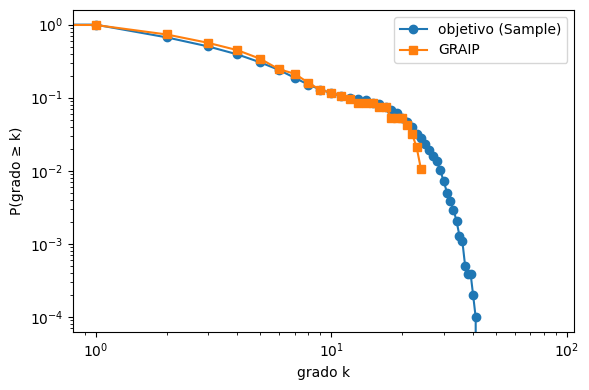

In [8]:
# Objetivo: estadísticas esperadas del grafo probabilístico
E_n, s_n, E_m, s_m, Ec, sc, E_N, s_N = Sample(G, 100, 8, four_counts)

# Resultado de GRAIP
n_out, m_out = Graipfinal.number_of_nodes(), Graipfinal.number_of_edges()
C_out = np.asarray(four_counts(Graipfinal), dtype=float)

print(f"Aristas esperadas sumando probabilidades: {sum(d['probability'] for *_, d in G.edges(data=True)):.1f}")
print(f"\n{'':8}{'objetivo':>14}{'GRAIP':>10}")
print(f"{'nodos':8}{E_n:>10.1f} ± {2*s_n:<5.1f}{n_out:>6}")
print(f"{'aristas':8}{E_m:>10.1f} ± {2*s_m:<5.1f}{m_out:>6}")

nombres = ["M1 (camino 3)", "M2 (triángulo)", "M3 (estrella)", "M4 (camino 4)",
           "M5 (paw)", "M6 (ciclo 4)", "M7 (diamante)", "M8 (clique 4)"]
print(f"\n{'graphlet':16}{'objetivo':>12}{'±2s':>10}{'GRAIP':>12}  ok?")
for i, nom in enumerate(nombres):
    ok = abs(C_out[i] - Ec[i]) <= 2 * sc[i]
    print(f"{nom:16}{Ec[i]:>12.1f}{2*sc[i]:>10.1f}{C_out[i]:>12.0f}  {'✓' if ok else '✗'}")

# Distribución de grados (complementaria acumulada, como usa Cost)
def ccdf(p):
    return np.cumsum(p[::-1])[::-1]

p_obj = E_N / E_n
deg_out = np.bincount([d for _, d in Graipfinal.degree()])
p_out = deg_out / n_out

plt.figure(figsize=(6, 4))
plt.loglog(range(len(p_obj)), ccdf(p_obj), "o-", label="objetivo (Sample)")
plt.loglog(range(len(p_out)), ccdf(p_out), "s-", label="GRAIP")
plt.xlabel("grado k"); plt.ylabel("P(grado ≥ k)")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(carpeta, f"{nombre}_grados.png"), dpi=150)
plt.show()

Grafo cargado: 341 nodos, 682 aristas
Iniciando sampleo.
Sampleo terminado.
Guardado en 'resultados_graip/': 120 nodos, 189 aristas

===== Escherichia_coli =====
Aristas esperadas sumando probabilidades: 325.4

              objetivo     GRAIP
nodos        168.3 ± 33.8    120
aristas      269.1 ± 44.6    189

graphlet            objetivo       ±2s       GRAIP  ok?
M1 (camino 3)         2876.7     472.2        1121  ✗
M2 (triángulo)          61.3      36.9          46  ✓
M3 (estrella)        28980.1    7830.6        5273  ✗
M4 (camino 4)         5059.7    1252.4        4064  ✓
M5 (paw)              1656.9    1249.2        1047  ✓
M6 (ciclo 4)           419.3     354.3          56  ✗
M7 (diamante)          515.0     409.4         101  ✗
M8 (clique 4)            4.3      11.0           9  ✓


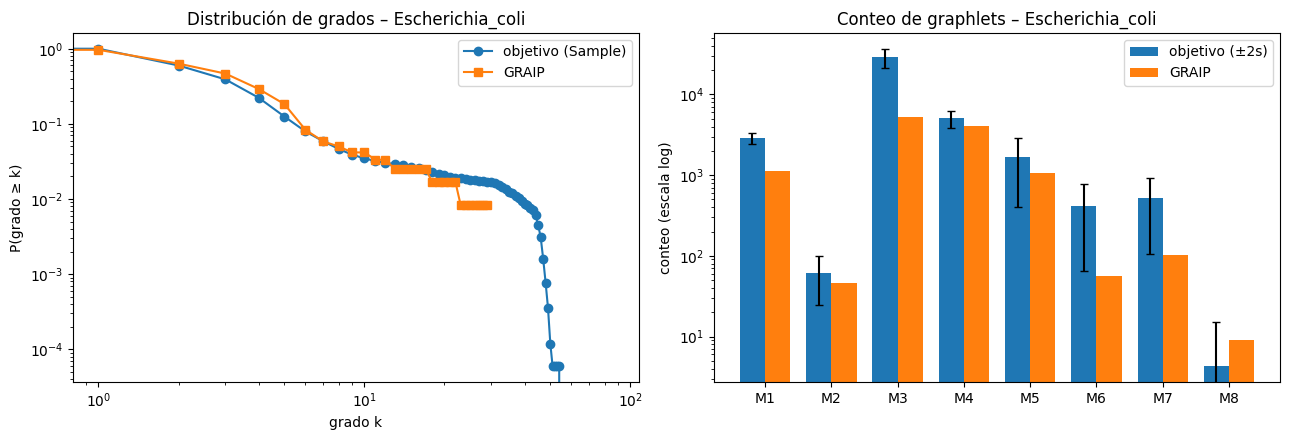

In [ ]:

def evaluar(G, H, nombre, carpeta, S=100):
    """Compara el grafo generado H contra las estadísticas esperadas de G (probabilístico)."""
    E_n, s_n, E_m, s_m, Ec, sc, E_N, s_N = Sample(G, S, 8, four_counts)

    n_out, m_out = H.number_of_nodes(), H.number_of_edges()
    C_out = np.asarray(four_counts(H), dtype=float)

    print(f"\n===== {nombre} =====")
    print(f"Aristas esperadas sumando probabilidades: {sum(d['probability'] for *_, d in G.edges(data=True)):.1f}")
    print(f"\n{'':8}{'objetivo':>14}{'GRAIP':>10}")
    print(f"{'nodos':8}{E_n:>10.1f} ± {2*s_n:<5.1f}{n_out:>6}")
    print(f"{'aristas':8}{E_m:>10.1f} ± {2*s_m:<5.1f}{m_out:>6}")

    nombres = ["M1 (camino 3)", "M2 (triángulo)", "M3 (estrella)", "M4 (camino 4)",
               "M5 (paw)", "M6 (ciclo 4)", "M7 (diamante)", "M8 (clique 4)"]
    print(f"\n{'graphlet':16}{'objetivo':>12}{'±2s':>10}{'GRAIP':>12}  ok?")
    for i, nom in enumerate(nombres):
        ok = abs(C_out[i] - Ec[i]) <= 2 * sc[i]
        print(f"{nom:16}{Ec[i]:>12.1f}{2*sc[i]:>10.1f}{C_out[i]:>12.0f}  {'✓' if ok else '✗'}")

    os.makedirs(carpeta, exist_ok=True)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

    ccdf = lambda p: np.cumsum(p[::-1])[::-1]
    p_obj = E_N / E_n
    p_out = np.bincount([d for _, d in H.degree()]) / n_out
    ax[0].loglog(range(len(p_obj)), ccdf(p_obj), "o-", label="objetivo (Sample)")
    ax[0].loglog(range(len(p_out)), ccdf(p_out), "s-", label="GRAIP")
    ax[0].set_xlabel("grado k"); ax[0].set_ylabel("P(grado ≥ k)")
    ax[0].set_title(f"Distribución de grados – {nombre}")
    ax[0].legend()

    # --- Histograma de graphlets ---
    x = np.arange(8)
    ancho = 0.38
    ax[1].bar(x - ancho/2, np.maximum(Ec, 0.1), ancho, yerr=2*sc, capsize=3,
              label="objetivo (±2s)", color="tab:blue")
    ax[1].bar(x + ancho/2, np.maximum(C_out, 0.1), ancho,
              label="GRAIP", color="tab:orange")
    ax[1].set_yscale("log")
    ax[1].set_xticks(x)
    ax[1].set_xticklabels([f"M{i+1}" for i in range(8)])
    ax[1].set_ylabel("conteo (escala log)")
    ax[1].set_title(f"Conteo de graphlets – {nombre}")
    ax[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(carpeta, f"{nombre}_comparacion.png"), dpi=150)
    plt.show()

# ---------------- E. coli ---------------- (REALIZADO CON IA)
ruta_gml = "datos/Escherichia_coli.gml"
carpeta = "resultados_graip"

G_coli = cargar_gml(ruta_gml)
print(f"Grafo cargado: {G_coli.number_of_nodes()} nodos, {G_coli.number_of_edges()} aristas")

Graipcoli = GRAIP(G_coli, S=100, max_it=1000, node_step=10, w=2/3)

os.makedirs(carpeta, exist_ok=True)
nombre = os.path.splitext(os.path.basename(ruta_gml))[0]

nx.write_edgelist(Graipcoli, os.path.join(carpeta, f"{nombre}_graip.edgelist"), data=False)
nx.write_graphml(Graipcoli, os.path.join(carpeta, f"{nombre}_graip.graphml"))
nx.write_gml(Graipcoli, os.path.join(carpeta, f"{nombre}_graip.gml"))
with open(os.path.join(carpeta, f"{nombre}_graip.pkl"), "wb") as f:
    pickle.dump(Graipcoli, f)

print(f"Guardado en '{carpeta}/': {Graipcoli.number_of_nodes()} nodos, {Graipcoli.number_of_edges()} aristas")

evaluar(G_coli, Graipcoli, nombre, carpeta)

In [13]:
# ---------------- T. nautili ----------------
ruta_gml = "datos/Thermococcus_nautili.gml"
carpeta = "resultados_graip"

G_termo = cargar_gml(ruta_gml)
print(f"Grafo cargado: {G_termo.number_of_nodes()} nodos, {G_termo.number_of_edges()} aristas")
GraipTermo = GRAIP(G_termo, S=1000, max_it=20000, node_step=5, max_rech=50, w=2/3)

os.makedirs(carpeta, exist_ok=True)
nombre = os.path.splitext(os.path.basename(ruta_gml))[0]

nx.write_edgelist(GraipTermo, os.path.join(carpeta, f"{nombre}_graip.edgelist"), data=False)
nx.write_graphml(GraipTermo, os.path.join(carpeta, f"{nombre}_graip.graphml"))
nx.write_gml(GraipTermo, os.path.join(carpeta, f"{nombre}_graip.gml"))
with open(os.path.join(carpeta, f"{nombre}_graip.pkl"), "wb") as f:
    pickle.dump(GraipTermo, f)

print(f"Guardado en '{carpeta}/': {GraipTermo.number_of_nodes()} nodos, {GraipTermo.number_of_edges()} aristas")

Grafo cargado: 158 nodos, 1275 aristas
Iniciando sampleo.
Sampleo terminado.
Guardado en 'resultados_graip/': 161 nodos, 1208 aristas


Iniciando sampleo.
Sampleo terminado.

===== Thermococcus_nautili =====
Aristas esperadas sumando probabilidades: 1070.5

              objetivo     GRAIP
nodos        152.3 ± 5.1     161
aristas     1069.0 ± 26.4   1208

graphlet            objetivo       ±2s       GRAIP  ok?
M1 (camino 3)        10733.6     419.5       12389  ✗
M2 (triángulo)        5370.1     378.7        4787  ✗
M3 (estrella)        32001.5    3354.3       39436  ✗
M4 (camino 4)        79729.8    5206.7       74811  ✓
M5 (paw)             91862.1    6235.5       80204  ✗
M6 (ciclo 4)          5204.3     891.6        4417  ✓
M7 (diamante)        32271.0    2816.7       29966  ✓
M8 (clique 4)        19409.0    2615.9       12074  ✗


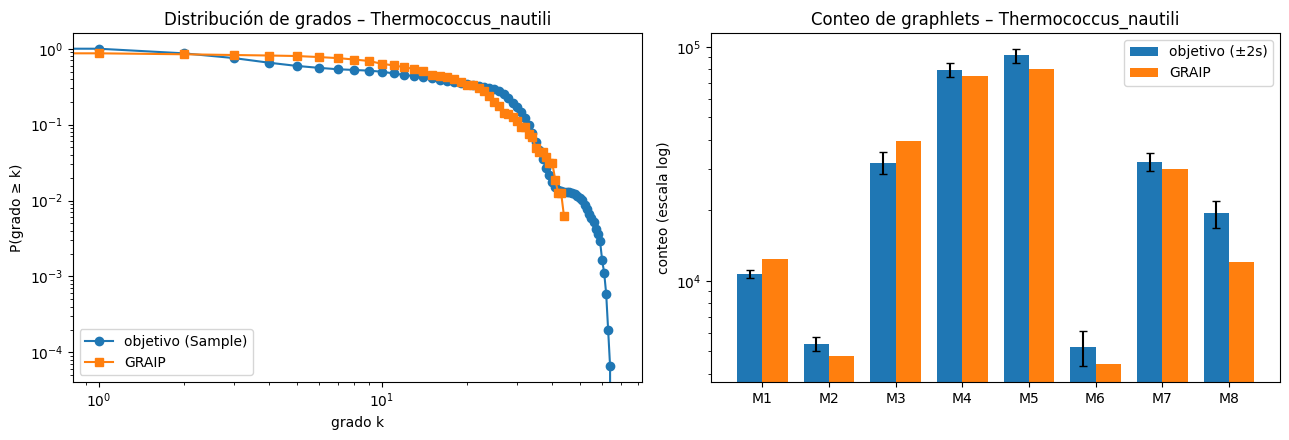

In [14]:
evaluar(G_termo, GraipTermo, "Thermococcus_nautili", carpeta)

# Animacion (Abstract)

100 cuadros; grafo final: 185 nodos, 249 aristas
GIF guardado en resultados_graip\graip_evolucion.gif (0.8 MB)


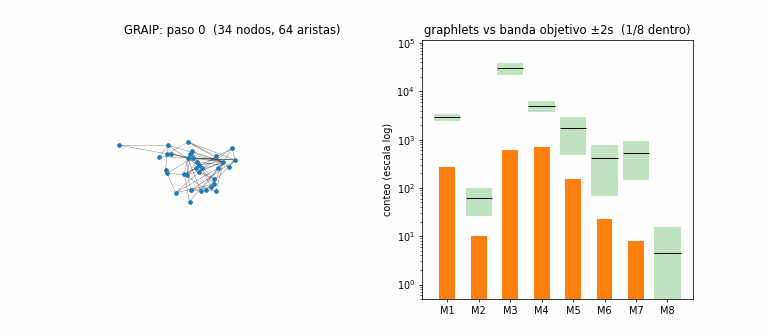

In [15]:
# REALIZADO CON IA

import os, random
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Rectangle
from IPython.display import Image, display

# ================= 1) Objetivo (se reutiliza `objetivo` si ya lo calculaste) =================
G_gif = G_coli
if "objetivo" in globals():
    tgt, S_obj = objetivo, 1000
else:
    tgt, S_obj = Sample(G_gif, 1000, 8, four_counts), 300
E_n, s_n, E_m, s_m, Ec, sc, E_N, s_N = tgt

# ================= 2) Copia del algoritmo que guarda cuadros (no toca tu GRAIP) =================
def graip_con_cuadros(max_it=20000, node_step=5, w=2/3, cada_aceptados=20, max_cuadros=100):
    graphlets, valid = construir_valid()
    bins, weights = BinDegrees(E_N, S_obj)
    bins = np.asarray(bins, dtype=int); weights = np.asarray(weights, dtype=float)
    E_p = weights / E_n
    wts = np.where(np.isclose(weights, np.round(weights)), np.round(weights), weights)
    necesario = np.maximum(np.maximum(wts - np.floor(wts), np.ceil(wts) - wts) * 1.1, 0.5)
    cota_nodos = np.where(np.diff(bins) == 1, 2 * s_N[bins[:-1]], necesario)
    s_p = cota_nodos / E_n
    b_c = 2 * sc
    CCg = 3 * Ec[1] / (Ec[0] + 3 * Ec[1])
    s_n_, s_m_ = max(s_n, 1e-9), max(s_m, 1e-9)
    max_rech = max(1, int(0.02 * E_m))

    N0 = max(round(E_n / 5), 3)
    k = max(1, min(round(E_m / E_n), N0 - 1))
    H = nx.barabasi_albert_graph(N0, k)
    C_H = np.asarray(four_counts(H), dtype=float)
    proximo_id = max(H.nodes) + 1
    rechazos, aceptados = 0, 0
    sig = lambda x: 1 / (1 + np.exp(-np.clip(x, -50, 50)))
    cuadros = [(0, H.copy(), C_H.copy())]                       # cuadro 0 = semilla BA

    for step in range(1, max_it + 1):
        n, m = H.number_of_nodes(), H.number_of_edges()
        P_H = histograma_bins(dist_grados([d for _, d in H.degree()]), bins)
        if dentro(P_H, E_p, s_p) and dentro(C_H, Ec, b_c):
            break
        r = random.random()
        if step % node_step == 0:
            if r > sig((n - E_n) / s_n_):
                u = proximo_id
                op = {"tipo": "add_node", "u": u, "aristas": add_node(H, u, CCg)}
            else:
                u = random.choice(list(H.nodes))
                op = {"tipo": "remove_node", "u": u, "aristas": list(H.edges(u))}
        else:
            if r > sig((m / n * E_n - E_m) / s_m_):
                arista = arista_nueva(H)
                if arista is None:
                    continue
                op = {"tipo": "add_edge", "u": None, "aristas": [arista]}
            else:
                if m == 0:
                    continue
                op = {"tipo": "remove_edge", "u": None, "aristas": [random.choice(list(H.edges))]}
        P_T = histograma_bins(dist_grados(grados_tras(H, op)), bins)
        C_T = contar_T(H, C_H, op, graphlets, valid)
        costo_H = Cost(P_H, C_H, E_p, s_p, Ec, b_c, w)
        costo_T = Cost(P_T, C_T, E_p, s_p, Ec, b_c, w)
        if costo_T < costo_H or rechazos >= max_rech:
            aplicar(H, op); C_H = C_T; rechazos = 0; aceptados += 1
            if op["tipo"] == "add_node":
                proximo_id += 1
            if aceptados % cada_aceptados == 0:
                cuadros.append((step, H.copy(), C_H.copy()))
        else:
            rechazos += 1
    cuadros.append((step, H.copy(), C_H.copy()))                # cuadro final
    if len(cuadros) > max_cuadros:                              # se adelgaza a ~max_cuadros, con primero y último
        idx = np.unique(np.linspace(0, len(cuadros) - 1, max_cuadros).astype(int))
        cuadros = [cuadros[i] for i in idx]
    return cuadros

cuadros = graip_con_cuadros()
print(f"{len(cuadros)} cuadros; grafo final: {cuadros[-1][1].number_of_nodes()} nodos, "
      f"{cuadros[-1][1].number_of_edges()} aristas")

# ================= 3) Posiciones fijas: un solo layout para todos los nodos que aparecen =================
U = nx.Graph()
for _, Hc, _ in cuadros:
    U.add_nodes_from(Hc.nodes); U.add_edges_from(Hc.edges)
pos = nx.spring_layout(U, seed=3, k=1.5 / np.sqrt(U.number_of_nodes()), iterations=200)
xs, ys = np.array(list(pos.values())).T
x0, x1 = np.percentile(xs, [1, 99]); y0, y1 = np.percentile(ys, [1, 99])   # ignora nodos sueltos lejanos
mx, my = 0.08 * (x1 - x0), 0.08 * (y1 - y0)

# ================= 4) Animación: grafo creciendo + barras de graphlets con banda ±2s =================
lo, hi = np.maximum(Ec - 2 * sc, 0.5), Ec + 2 * sc
ymax = 3 * max(hi.max(), max(C.max() for *_, C in cuadros))
x = np.arange(8)

fig, (axg, axb) = plt.subplots(1, 2, figsize=(11, 4.8))

def dibujar(j):
    paso, Hc, C = cuadros[j]
    axg.clear(); axb.clear()
    nx.draw_networkx_edges(Hc, pos, ax=axg, width=0.5, alpha=0.5)
    nx.draw_networkx_nodes(Hc, pos, ax=axg, node_size=14, node_color="tab:blue")
    axg.set_xlim(x0 - mx, x1 + mx); axg.set_ylim(y0 - my, y1 + my)
    axg.axis("off")
    axg.set_title(f"GRAIP: paso {paso}  ({Hc.number_of_nodes()} nodos, {Hc.number_of_edges()} aristas)")

    for i in range(8):
        axb.add_patch(Rectangle((i - 0.42, lo[i]), 0.84, hi[i] - lo[i], color="tab:green", alpha=0.3, lw=0))
    ok = np.abs(C - Ec) <= 2 * sc
    h = np.maximum(C, 0.5)
    axb.bar(x, h - 0.5, 0.5, bottom=0.5, color=np.where(ok, "tab:green", "tab:orange"))
    axb.hlines(Ec, x - 0.42, x + 0.42, color="k", lw=1)
    axb.set_yscale("log"); axb.set_ylim(0.5, ymax)
    axb.set_xticks(x); axb.set_xticklabels([f"M{i+1}" for i in range(8)])
    axb.set_ylabel("conteo (escala log)")
    axb.set_title(f"graphlets vs banda objetivo ±2s  ({int(ok.sum())}/8 dentro)")

frames = list(range(len(cuadros))) + [len(cuadros) - 1] * 10     # pausa en el cuadro final
anim = FuncAnimation(fig, dibujar, frames=frames, interval=120)
os.makedirs(carpeta, exist_ok=True)
ruta_gif = os.path.join(carpeta, "graip_evolucion.gif")
anim.save(ruta_gif, writer=PillowWriter(fps=8), dpi=70)
plt.close(fig)
print(f"GIF guardado en {ruta_gif} ({os.path.getsize(ruta_gif)/1e6:.1f} MB)")
display(Image(filename=ruta_gif))

# Validación

In [10]:
import time, pickle, hashlib
from pathlib import Path
from IPython.display import Image, display
import run_validation as rv
import wwl_validation as wv

RUTA_GML  = "datos/Escherichia_coli.gml"   # red probabilística a validar
NOMBRE    = "ecoli"
S_GRAIP   = 1000        # mundos posibles para las cotas (tu notebook usa 100; el paper, 10 000)
MAX_IT    = None        # None -> 100 * E_m pasos por grafo, como en el paper (tu notebook usa 1000)
NODE_STEP = 10
W_GRAIP   = 2/3
N_GRAFOS  = 100         # grafos por conjunto
H_LIST    = [0, 1, 2, 3]
N_JOBS    = 4           # solo para las distancias WWL; GRAIP se genera en serie
SENS_N    = 50
SEED      = 0
SALIDA    = Path("results") / NOMBRE

G_val = cargar_gml(RUTA_GML)                      # tu función: atributo 'probability'
G_val = nx.convert_node_labels_to_integers(G_val)
Gu_val = nx.Graph()                               # mismo grafo con el atributo 'p' que usa run_validation
for u, v, d in G_val.edges(data=True):
    Gu_val.add_edge(u, v, p=float(d["probability"]))
print(Gu_val.number_of_nodes(), "nodos,", Gu_val.number_of_edges(), "aristas")

341 nodos, 682 aristas


In [11]:
# ===== C. GENERADOR Y PRUEBA DE TIEMPO =====
E_m_val = Sample(G_val, S_GRAIP, 8, four_counts)[2]          # aristas esperadas
MAX_IT_EFECTIVO = MAX_IT or int(100 * E_m_val)

def generate(_Gu, seed):
    """Interfaz que espera run_validation: (red incierta, semilla) -> nx.Graph."""
    random.seed(seed); np.random.seed(seed % (2 ** 32))
    return GRAIP(G_val, S_GRAIP, MAX_IT_EFECTIVO, NODE_STEP, w=W_GRAIP)

t0 = time.time()
H_prueba = generate(Gu_val, 12345)
dt = time.time() - t0
print(f"1 grafo GRAIP: {dt:.1f} s ({H_prueba.number_of_nodes()} nodos, {H_prueba.number_of_edges()} aristas)")
print(f"-> {N_GRAFOS} grafos tardarán ~{dt * N_GRAFOS / 60:.1f} min. Ajusta N_GRAFOS / MAX_IT si es demasiado.")

Iniciando sampleo.
Sampleo terminado.
1 grafo GRAIP: 14.5 s (188 nodos, 276 aristas)
-> 100 grafos tardarán ~24.1 min. Ajusta N_GRAFOS / MAX_IT si es demasiado.


  [graip] 1/100 grafos (14.0 s/grafo, ~23.1 min restantes)
  [graip] 2/100 grafos (13.3 s/grafo, ~21.7 min restantes)
  [graip] 3/100 grafos (13.0 s/grafo, ~21.0 min restantes)
  [graip] 4/100 grafos (13.2 s/grafo, ~21.2 min restantes)
  [graip] 5/100 grafos (13.1 s/grafo, ~20.7 min restantes)
  [graip] 6/100 grafos (11.2 s/grafo, ~17.6 min restantes)
  [graip] 7/100 grafos (11.4 s/grafo, ~17.6 min restantes)
  [graip] 8/100 grafos (11.6 s/grafo, ~17.7 min restantes)
  [graip] 9/100 grafos (11.7 s/grafo, ~17.8 min restantes)
  [graip] 10/100 grafos (11.8 s/grafo, ~17.6 min restantes)
  [graip] 11/100 grafos (11.9 s/grafo, ~17.6 min restantes)
  [graip] 12/100 grafos (11.8 s/grafo, ~17.3 min restantes)
  [graip] 13/100 grafos (11.9 s/grafo, ~17.3 min restantes)
  [graip] 14/100 grafos (11.9 s/grafo, ~17.1 min restantes)
  [graip] 15/100 grafos (11.9 s/grafo, ~16.9 min restantes)
  [graip] 16/100 grafos (12.0 s/grafo, ~16.8 min restantes)
  [graip] 17/100 grafos (12.4 s/grafo, ~17.2 min 

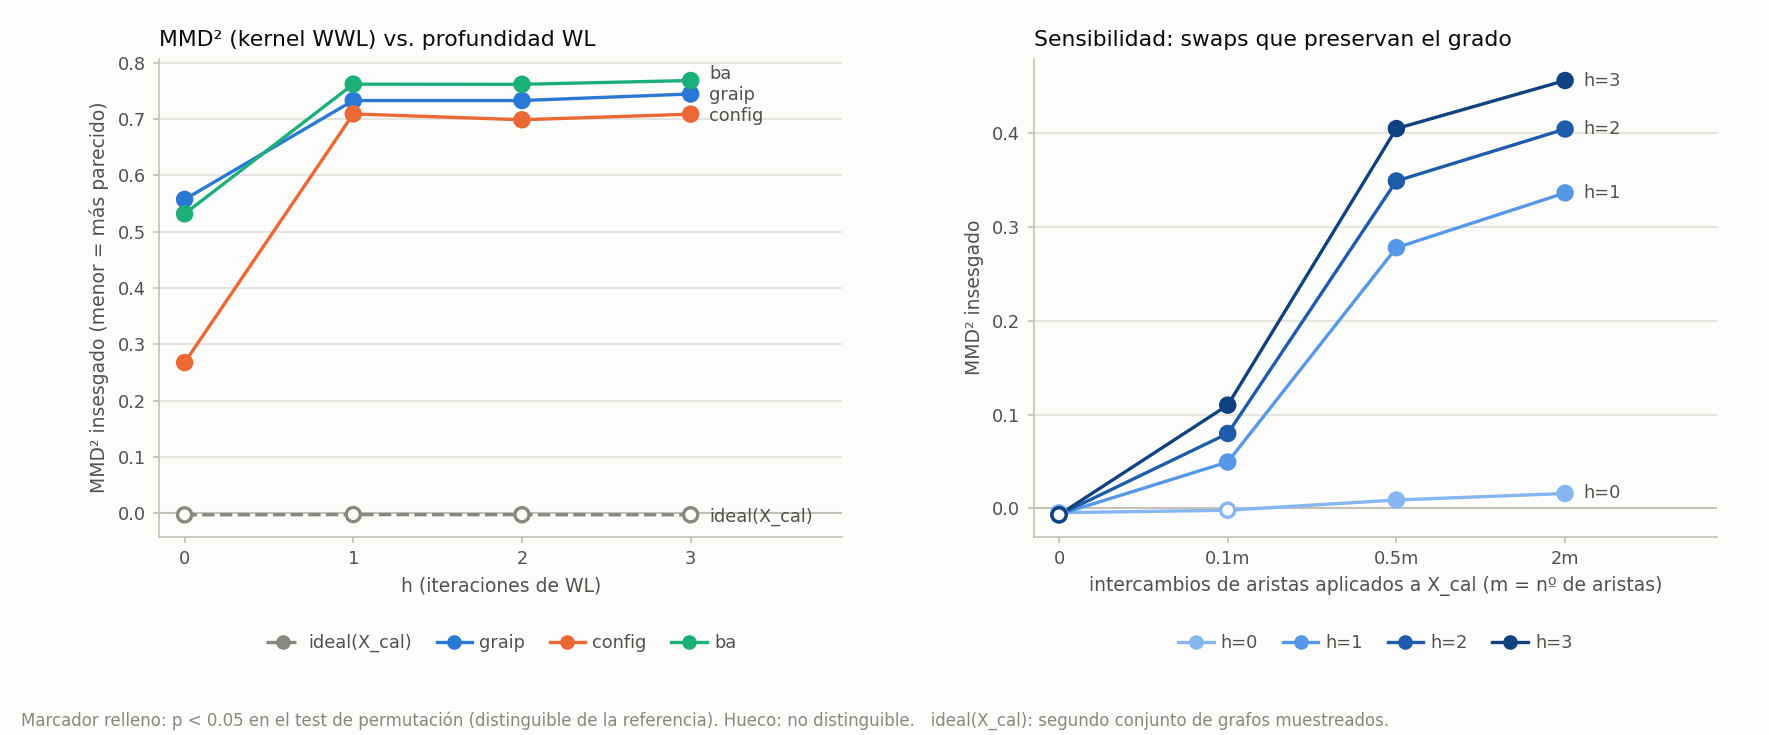

In [12]:
#VALIDACIÓN  (reanudable: todo se guarda en results/<NOMBRE>/cache_*) 
N = N_GRAFOS
cache = SALIDA / f"cache_{rv.network_fingerprint(Gu_val)}"
cache.mkdir(parents=True, exist_ok=True)

# referencia: 2N mundos posibles (N de referencia + N de calibración "ideal")
X_all = rv.get_cached("X", lambda: wv.sample_possible_graphs(Gu_val, 2 * N, SEED), 2 * N, cache)
X_ref, X_cal = X_all[:N], X_all[N:2 * N]

# grafos generados: GRAIP + baselines (configuración y BA dual)
models = {}
models["graip"]  = rv.generate_cached("graip", generate, Gu_val, N, SEED + 1_000_000, 1, cache)
models["config"] = rv.get_cached("config", lambda: wv.make_config_graphs(Gu_val, N, SEED + 2_000_000), N, cache)
models["ba"]     = rv.get_cached("ba", lambda: wv.make_dual_ba_graphs(X_ref, N, SEED + 3_000_000), N, cache)

common = dict(solver="emd", reg=0.05, n_jobs=N_JOBS, cache_dir=cache, n_perm=1000, seed=SEED, do_c2st=True)
rows = wv.run_wwl_validation(X_ref, X_cal, models, h_list=H_LIST, baseline="config", **common)
wv.write_csv(rows, SALIDA / "results.csv")
rv.print_table(rows, f"Resultados ({NOMBRE})")

sens_rows = wv.run_sensitivity(X_ref, X_cal, fracs=[0.1, 0.5, 2.0], sens_n=SENS_N, h_list=H_LIST,
                               **{**common, "do_c2st": False})
wv.write_csv(sens_rows, SALIDA / "sensitivity.csv")
rv.print_table(sens_rows, "Sensibilidad")

import matplotlib, matplotlib.pyplot as plt
_backend = matplotlib.get_backend()   # plot_summary cambia el backend a "Agg"; se restaura abajo
rv.plot_summary(rows, sens_rows, SALIDA / "summary.png")
plt.switch_backend(_backend)
display(Image(str(SALIDA / "summary.png")))

# Más testeos